In [ ]:
import numpy as np
import pandas as pd
from castvalue.bess.daa import Optimizer
import matplotlib.pyplot as plt

# 1. Load data
df = pd.read_csv("../data/master_energy_data_v2.csv")
df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], utc=True)

# 2. Initialize the optimizer
solverpath_exe = "/opt/anaconda3/bin/glpsol"
opt = Optimizer(solverpath_exe)

# 3. Setup Indexing — trim to complete days
num_days = len(df) // 96
df = df.iloc[:num_days * 96].reset_index(drop=True)
df['day_index'] = np.repeat(np.arange(1, num_days + 1), 96)
dates = df.groupby('day_index')['timestamp_utc'].first().dt.date.values

# 4. Parameters
POWER_CAP_MW = 1.0
ENERGY_CAP_MWH = 2.0
N_CYCLES_PER_DAY = 1.0
RTE = 0.85

SCENARIOS = {
    "Persistence":      {"daa_f": "daa_persistence_forecast", "perfect": False},
    "Electricity Maps": {"daa_f": "daa_em_forecast",          "perfect": False},
    "Perfect":          {"daa_f": "daa_actuals",              "perfect": True},
}

results = []
daily_margins_tracking = {sc: [] for sc in SCENARIOS}

# 5. Run the Backtest (rolling SOC, opportunity-cost bidding, RTE)
for sc_name, cols in SCENARIOS.items():
    annual_profit = 0
    carryover_soc = 0.0
    print(f"Running Scenario: {sc_name}...")

    for d in range(1, num_days + 1):
        day_data = df[df['day_index'] == d]
        f_vec = {"daa": day_data[cols["daa_f"]].tolist()}
        a_vec = {"daa": day_data["daa_actuals"].tolist()}

        out = opt.run_day(f_vec, a_vec, POWER_CAP_MW, ENERGY_CAP_MWH,
                          N_CYCLES_PER_DAY, rte=RTE, initial_soc=carryover_soc,
                          perfect_foresight=cols["perfect"])
        daily_margins_tracking[sc_name].append(out["profit_total"])
        annual_profit += out["profit_total"]
        carryover_soc = out["end_soc"]

    results.append({"Scenario": sc_name, "Annual Margin": annual_profit})

# 6. Build Results DataFrame
results_df = pd.DataFrame(results)
persistence_margin = results_df.loc[results_df['Scenario'] == 'Persistence',      'Annual Margin'].values[0]
em_margin          = results_df.loc[results_df['Scenario'] == 'Electricity Maps',  'Annual Margin'].values[0]
perfect_margin     = results_df.loc[results_df['Scenario'] == 'Perfect',           'Annual Margin'].values[0]

# 7. Cumulative Margin Plot
plt.figure(figsize=(12, 7))
colors = {"Persistence": "orange", "Electricity Maps": "dodgerblue", "Perfect": "green"}

for sc_name, daily_profits in daily_margins_tracking.items():
    cumulative_profit = np.cumsum(daily_profits)
    plt.plot(dates, cumulative_profit,
             label=f"{sc_name} (Total: €{cumulative_profit[-1]:,.0f})",
             color=colors[sc_name], linewidth=2)

plt.title(f"CastValue v1.1 — Cumulative DAA Margin (RTE={RTE:.0%}, Rolling SOC)", fontsize=14)
plt.ylabel("Cumulative Margin [EUR/MW]")
plt.xlabel("Date")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Annual Results Bar Chart
scenarios_plot = ["Electricity Maps", "Perfect"]
annual_margins = [em_margin, perfect_margin]
bar_colors = ["dodgerblue", "green"]

y_min = persistence_margin * 0.92
y_max = perfect_margin * 1.10

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(scenarios_plot, annual_margins, color=bar_colors, width=0.5)
ax.axhline(persistence_margin, color='orange', linestyle='--', linewidth=1.5,
           label=f'Persistence baseline  €{persistence_margin:,.0f}')
ax.set_ylim(y_min, y_max)
ax.set_ylabel("Total DAA Margin [EUR/MW]")
ax.set_title(f"CastValue v1.1 — DAA Margin over {num_days} days (RTE={RTE:.0%})", fontsize=14)
ax.legend(loc='lower right')

for i, (margin, label) in enumerate(zip(annual_margins, scenarios_plot)):
    ax.text(i, margin + (y_max - y_min) * 0.012, f"€{margin:,.0f}", ha='center', fontweight='bold')
    delta = margin - persistence_margin
    ax.annotate('', xy=(i, margin), xytext=(i, persistence_margin),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5))
    ax.text(i + 0.22, (margin + persistence_margin) / 2,
            f"+€{delta:,.0f}", color='red', fontsize=11, fontweight='bold', va='center')

plt.tight_layout()
plt.show()

print(f"\nCastValue (EM):     +€{em_margin - persistence_margin:,.0f} /MW")
print(f"Cost of Error (EM): €{perfect_margin - em_margin:,.0f} /MW")
print(f"Profit Capture:     {em_margin / perfect_margin * 100:.1f}%")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_comparison(day_idx):
    """
    Visualizes price forecasts vs actuals, dispatch decisions with
    bid/ask prices, fill status, SOC, and cumulative margins.
    """
    day_data = df[df['day_index'] == day_idx].copy()
    if day_data.empty:
        print(f"Error: Day index {day_idx} contains no data.")
        return

    actual_prices = day_data["daa_actuals"].values[:96]
    date_label = day_data['timestamp_utc'].iloc[0].date()

    plot_scenarios = {
        "Persistence":      day_data["daa_persistence_forecast"].values[:96],
        "Electricity Maps": day_data["daa_em_forecast"].values[:96],
        "Perfect":          actual_prices,
    }
    colors_map = {"Persistence": "orange", "Electricity Maps": "dodgerblue",
                  "Perfect": "green"}

    results_cache = {}
    pf = POWER_CAP_MW / 4.0

    for name, price_vec in plot_scenarios.items():
        f_vec = {"daa": list(price_vec)}
        a_vec = {"daa": list(actual_prices)}
        out = opt.run_day(f_vec, a_vec, POWER_CAP_MW, ENERGY_CAP_MWH,
                          N_CYCLES_PER_DAY, rte=RTE,
                          perfect_foresight=(name == "Perfect"))
        results_cache[name] = out

    scenario_order = ["Persistence", "Electricity Maps", "Perfect"]
    hours = np.arange(96) / 4

    fig, axs = plt.subplots(len(scenario_order), 1, figsize=(16, 5 * len(scenario_order)),
                            sharex=True)
    fig.suptitle(f"Day {day_idx} ({date_label}) — v1.1 Opportunity-Cost Bidding (RTE={RTE:.0%})",
                 fontsize=15, fontweight="bold", y=1.0)

    for i, name in enumerate(scenario_order):
        ax = axs[i]
        out = results_cache[name]
        color = colors_map[name]
        cha_plan = np.array(out["cha_planned"])
        dis_plan = np.array(out["dis_planned"])
        cha_final = np.array(out["cha"])
        dis_final = np.array(out["dis"])
        bid = np.array(out["bid_prices"])
        fill = np.array(out["fill_mask"])
        soc = np.array(out["soc"])

        # Price lines
        ax.plot(hours, actual_prices, color="#1F2937", linewidth=1.5, label="Actual")
        if name != "Perfect":
            ax.plot(hours, plot_scenarios[name], color=color, linewidth=1.2,
                    linestyle="--", alpha=0.7, label="Forecast")

        # Shade MTUs and show bid markers (charge=blue, discharge=green, rejected=red)
        from matplotlib.patches import Patch
        CHA_COLOR = "#3B82F6"
        DIS_COLOR = "#10B981"
        REJ_COLOR = "#EF4444"
        for q in range(96):
            h = hours[q]
            w = 0.25
            if cha_plan[q] > 0.01:
                fc = CHA_COLOR if fill[q] > 0.5 else REJ_COLOR
                ax.axvspan(h, h + w, alpha=0.22 if fill[q] > 0.5 else 0.12, color=fc)
                ax.plot([h + w/2], [bid[q]], marker="^", color=fc, markersize=4, alpha=0.85)
            elif dis_plan[q] > 0.01:
                fc = DIS_COLOR if fill[q] > 0.5 else REJ_COLOR
                ax.axvspan(h, h + w, alpha=0.22 if fill[q] > 0.5 else 0.12, color=fc)
                ax.plot([h + w/2], [bid[q]], marker="v", color=fc, markersize=4, alpha=0.85)

        ax.set_ylabel("EUR/MWh")

        # SOC on right axis
        ax2 = ax.twinx()
        ax2.fill_between(hours, 0, soc, color="#9CA3AF", alpha=0.12)
        ax2.plot(hours, soc, color="#6B7280", linewidth=1.3, alpha=0.7)
        ax2.set_ylim(0, ENERGY_CAP_MWH * 1.1)
        ax2.set_ylabel("SOC (MWh)", color="#6B7280")

        n_active = int(np.sum((cha_plan > 0.01) | (dis_plan > 0.01)))
        n_filled = int(np.sum(fill))
        margin = np.sum((dis_final - cha_final) * actual_prices) * pf
        end_soc = out["end_soc"]
        soc_suffix = f" | End SOC: {end_soc:.2f} MWh (carried over)" if end_soc > 0.01 else f" | End SOC: 0.00 MWh"
        ax.set_title(f"{name} — {n_filled}/{n_active} filled | "
                     f"Margin: €{margin:.0f}{soc_suffix}",
                     fontsize=11, fontweight="bold", color=color)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper left", fontsize=9)

    axs[-1].set_xlabel("Hour (UTC)")
    axs[-1].set_xlim(0, 24)
    axs[-1].set_xticks(range(0, 25, 3))
    plt.tight_layout()
    plt.show()

# Run for an example day
plot_comparison(44)


--- THE PARADOX DAYS (Electricity Maps) ---
Bad Forecast, Good Capture:
  Day 121 (2026-02-16) | MAE: 26.11 | Lost: €3.65



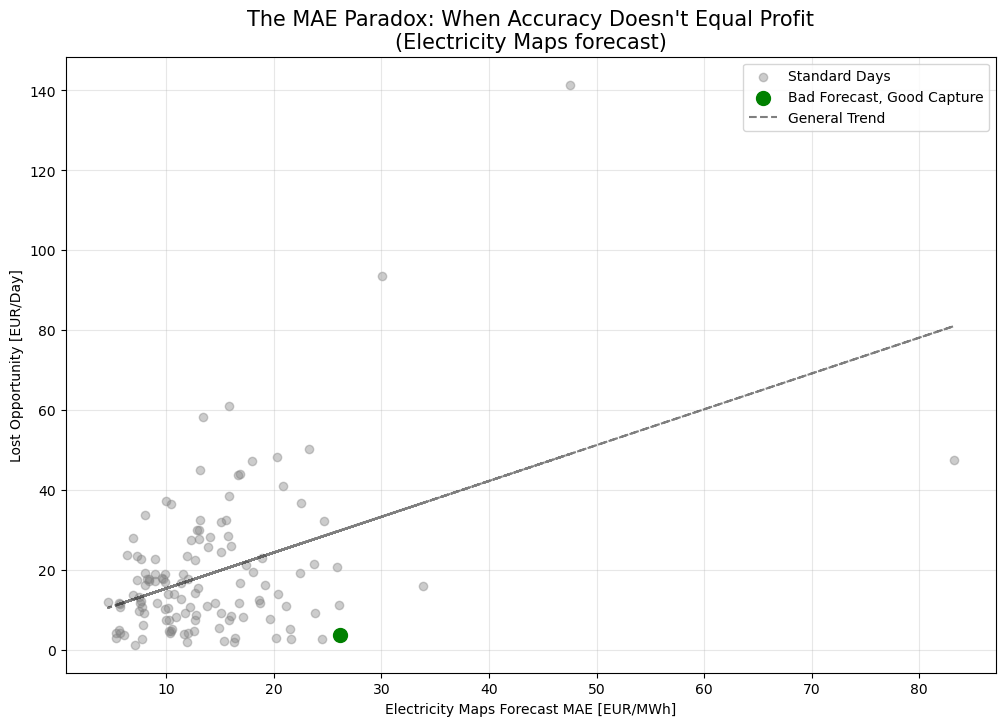

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate Daily MAE and Lost Opportunity (using Electricity Maps as reference provider)
correlation_analysis = []

for d in range(1, num_days + 1):
    day_data = df[df['day_index'] == d]
    if day_data.empty:
        continue

    actuals  = day_data['daa_actuals'].values
    em_f     = day_data['daa_em_forecast'].values
    date     = day_data['timestamp_utc'].iloc[0].date()

    mae = np.mean(np.abs(em_f - actuals))

    perf_margin = daily_margins_tracking["Perfect"][d - 1]
    em_margin_d = daily_margins_tracking["Electricity Maps"][d - 1]
    lost_opp    = perf_margin - em_margin_d

    correlation_analysis.append({
        "day_index":        d,
        "date":             date,
        "mae":              mae,
        "lost_opportunity": lost_opp,
        "perf_margin":      perf_margin,
    })

corr_df = pd.DataFrame(correlation_analysis)

# 2. Identify the Paradox Days
high_mae_no_missed = corr_df[
    (corr_df['lost_opportunity'] <= corr_df['lost_opportunity'].quantile(0.25)) &
    (corr_df['mae'] > corr_df['mae'].quantile(0.95))
]
low_mae_high_missed = corr_df[
    (corr_df['mae'] < corr_df['mae'].quantile(0.25)) &
    (corr_df['lost_opportunity'] > corr_df['lost_opportunity'].quantile(0.90))
]

# 3. Print Results
print("--- THE PARADOX DAYS (Electricity Maps) ---")
if not high_mae_no_missed.empty:
    best = high_mae_no_missed.sort_values('mae', ascending=False).iloc[0]
    print(f"Bad Forecast, Good Capture:")
    print(f"  Day {best['day_index']} ({best['date']}) | MAE: {best['mae']:.2f} | Lost: €{best['lost_opportunity']:.2f}\n")

if not low_mae_high_missed.empty:
    worst = low_mae_high_missed.sort_values('lost_opportunity', ascending=False).iloc[0]
    print(f"Good Forecast, Bad Capture:")
    print(f"  Day {worst['day_index']} ({worst['date']}) | MAE: {worst['mae']:.2f} | Lost: €{worst['lost_opportunity']:.2f}")

# 4. Plotting
plt.figure(figsize=(12, 8))
plt.scatter(corr_df['mae'], corr_df['lost_opportunity'], alpha=0.4, color='gray', label='Standard Days')

if not high_mae_no_missed.empty:
    plt.scatter(high_mae_no_missed['mae'], high_mae_no_missed['lost_opportunity'],
                color='green', s=100, label='Bad Forecast, Good Capture')
if not low_mae_high_missed.empty:
    plt.scatter(low_mae_high_missed['mae'], low_mae_high_missed['lost_opportunity'],
                color='red', s=100, label='Good Forecast, Bad Capture')

m, b = np.polyfit(corr_df['mae'], corr_df['lost_opportunity'], 1)
plt.plot(corr_df['mae'], m * corr_df['mae'] + b, color='black', linestyle='--', alpha=0.5, label='General Trend')

plt.title("The MAE Paradox: When Accuracy Doesn't Equal Profit\n(Electricity Maps forecast)", fontsize=15)
plt.xlabel("Electricity Maps Forecast MAE [EUR/MWh]")
plt.ylabel("Lost Opportunity [EUR/Day]")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_paradox_deep_dive(day_idx_a, day_idx_b):
    """
    Deep dive on two days comparing Electricity Maps forecast accuracy
    vs. dispatch profit capture under v1.1 bidding.
    """
    days = [day_idx_a, day_idx_b]
    fig, axs = plt.subplots(3, 2, figsize=(18, 15), sharex='col')
    pf = POWER_CAP_MW / 4.0
    x = np.arange(96) / 4  # hours

    for col, day_idx in enumerate(days):
        day_data = df[df['day_index'] == day_idx].copy().iloc[:96]
        if day_data.empty:
            print(f"Day {day_idx} not found.")
            continue

        actuals    = day_data["daa_actuals"].values
        provider_f = day_data["daa_em_forecast"].values
        date       = day_data['timestamp_utc'].iloc[0].date()
        mae        = np.mean(np.abs(actuals - provider_f))

        scenarios = {"Perfect": actuals, "Electricity Maps": provider_f}
        results = {}

        for name, prices in scenarios.items():
            f_vec = {"daa": list(prices)}
            a_vec = {"daa": list(actuals)}
            out = opt.run_day(f_vec, a_vec, POWER_CAP_MW, ENERGY_CAP_MWH,
                              N_CYCLES_PER_DAY, rte=RTE,
                              perfect_foresight=(name == "Perfect"))
            results[name] = out

        em_profit = results["Electricity Maps"]["profit_total"]
        pf_profit = results["Perfect"]["profit_total"]
        capture_rate = (em_profit / pf_profit * 100) if pf_profit > 0 else 0

        # ROW 1: Price & Forecast
        axs[0, col].plot(x, actuals, color='black', label='Actual Price', linewidth=2.5)
        axs[0, col].plot(x, provider_f, '--', color='dodgerblue', label='Electricity Maps', alpha=0.8)
        title_type = "BAD FORECAST, GOOD CAPTURE" if mae > 40 else "GOOD FORECAST, BAD CAPTURE"
        axs[0, col].set_title(
            f"Day {day_idx} ({date}) — {title_type}\n"
            f"MAE: {mae:.2f} EUR/MWh | Capture: {capture_rate:.1f}%",
            fontsize=13, fontweight='bold', pad=15)
        axs[0, col].legend(loc='upper left')
        axs[0, col].grid(alpha=0.3)

        # ROW 2: Perfect Dispatch
        cha_pf = np.array(results["Perfect"]["cha"])
        dis_pf = np.array(results["Perfect"]["dis"])
        axs[1, col].bar(x,  cha_pf * pf, width=0.2, color='green', alpha=0.3, label='Charge')
        axs[1, col].bar(x, -dis_pf * pf, width=0.2, color='green', alpha=0.8, label='Discharge')
        axs[1, col].set_title(f"Perfect Foresight (€{pf_profit:.0f})", fontsize=12)
        axs[1, col].axhline(0, color='black', linewidth=0.5)
        axs[1, col].set_ylim(-pf * 1.2, pf * 1.2)

        # ROW 3: EM Dispatch
        cha_em = np.array(results["Electricity Maps"]["cha"])
        dis_em = np.array(results["Electricity Maps"]["dis"])
        fill = np.array(results["Electricity Maps"]["fill_mask"])
        cha_plan = np.array(results["Electricity Maps"]["cha_planned"])
        dis_plan = np.array(results["Electricity Maps"]["dis_planned"])
        n_filled = int(fill.sum())
        n_active = int(np.sum((cha_plan > 0.01) | (dis_plan > 0.01)))
        axs[2, col].bar(x,  cha_em * pf, width=0.2, color='dodgerblue', alpha=0.3, label='Charge')
        axs[2, col].bar(x, -dis_em * pf, width=0.2, color='dodgerblue', alpha=0.8, label='Discharge')
        axs[2, col].set_title(f"Electricity Maps (€{em_profit:.0f} | {n_filled}/{n_active} filled)", fontsize=12)
        axs[2, col].axhline(0, color='black', linewidth=0.5)
        axs[2, col].set_ylim(-pf * 1.2, pf * 1.2)
        axs[2, col].set_xlabel("Hour (UTC)")

    plt.suptitle("The MAE Paradox — Deep Dive (v1.1)", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

# Find paradox days from Cell 3
if not high_mae_no_missed.empty and not low_mae_high_missed.empty:
    plot_paradox_deep_dive(
        int(high_mae_no_missed.sort_values("mae", ascending=False).iloc[0]["day_index"]),
        int(low_mae_high_missed.sort_values("lost_opportunity", ascending=False).iloc[0]["day_index"])
    )
